# Task 5 – Feature Engineering & Feature Selection
## AI-Based Product Review Sentiment Analysis

## 2. AIM
To engineer meaningful features from product review data, analyze feature relationships, determine feature importance, and select the most relevant features for machine learning-based sentiment classification.

## 3. PROBLEM STATEMENT
Raw product reviews are textual data and cannot be directly used by most traditional machine learning algorithms. Therefore, meaningful numerical features must be extracted and the most informative features must be selected to improve model efficiency and predictive performance.

## 4. OBJECTIVES
1. Analyze the cleaned product review dataset.
2. Generate meaningful text-based features.
3. Convert review text into numerical features using TF-IDF.
4. Analyze feature relationships using correlation analysis.
5. Determine feature importance using multiple techniques.
6. Remove irrelevant/redundant features.
7. Select the most informative features.
8. Generate the final feature matrix for Task 6.

## 5. DATASET DESCRIPTION
The dataset consists of cleaned product reviews and their corresponding sentiment labels. We are provided with the full dataset (`clean_product_reviews.csv`), as well as training and testing sets (`X_train.csv`, `X_test.csv`).

## 6. IMPORT LIBRARIES
Importing all required libraries for feature engineering, machine learning, and visualization.

In [16]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import mutual_info_classif, SelectKBest, chi2
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import joblib
import warnings
warnings.filterwarnings('ignore')

## 7. LOAD DATASET
Loading `clean_product_reviews.csv`, `X_train.csv`, and `X_test.csv`. We check for existence first to avoid errors.

In [17]:
files_needed = ['clean_product_reviews.csv', 'X_train.csv', 'X_test.csv']
print("Files in directory:", os.listdir())
for f in files_needed:
    if not os.path.exists(f):
        print(f"Required file not found. Please upload the file: {f}")

# Load the datasets
df = pd.read_csv('clean_product_reviews.csv')
X_train_df = pd.read_csv('X_train.csv')
X_test_df = pd.read_csv('X_test.csv')

print("--- File Names & Shapes ---")
print("clean_product_reviews.csv shape:", df.shape)
print("X_train.csv shape:", X_train_df.shape)
print("X_test.csv shape:", X_test_df.shape)

print("\n--- First 5 rows of clean_product_reviews ---")
display(df.head())

print("\n--- Column Names ---")
print(df.columns.tolist())

print("\n--- Data Types ---")
print(df.dtypes)

print("\n--- Missing Values ---")
print(df.isnull().sum())

print("\n--- Duplicate Records ---")
print(df.duplicated().sum())


Files in directory: ['task5_feature_engineering.ipynb', 'task5_selected_features.csv', 'task5_mutual_information.png', 'task5_tfidf_vectorizer.pkl', 'task5_feature_count_comparison.png', 'task5_feature_selection_validation.png', 'remove_uppercase.py', 'task5_random_forest_importance.png', 'task5_feature_engineering_report.csv', 'check_var.py', 'task5_review_length.png', 'generate_notebook.py', 'task5_correlation_heatmap.png', 'task5_correlation_matrix.csv', 'X_train.csv', 'fix_structural_features.py', 'Task_5_Feature_Engineering_and_Feature_Selection.ipynb', 'task5_feature_matrix.csv', 'task5_sentiment_distribution.png', 'head_nb.py', 'check_negative.py', 'test_min.py', 'check_full.py', 'task5_chi_square.png', 'check_nans.py', 'fix_notebook.py', 'X_test.csv', 'clean_product_reviews.csv', 'task5_feature_importance_report.csv', 'run_notebook_logic.py', 'task5_word_count.png']
--- File Names & Shapes ---
clean_product_reviews.csv shape: (399996, 6)
X_train.csv shape: (319996, 1)
X_test.cs

,review_text,sentiment_numeric,label_raw,clean_review,review_length,word_count
0,Great CD: My lovely Pat has one of the GREAT v...,1,__label__2,great cd: my lovely pat has one of the great v...,533,106
1,One of the best game music soundtracks - for a...,1,__label__2,one of the best game music soundtracks - for a...,816,148
2,Batteries died within a year ...: I bought thi...,0,__label__1,batteries died within a year ...: i bought thi...,335,60
3,"works fine, but Maha Energy is better: Check o...",1,__label__2,"works fine, but maha energy is better: check o...",229,37
4,Great for the non-audiophile: Reviewed quite a...,1,__label__2,great for the non-audiophile: reviewed quite a...,412,69



--- Column Names ---
['review_text', 'sentiment_numeric', 'label_raw', 'clean_review', 'review_length', 'word_count']

--- Data Types ---
review_text          object
sentiment_numeric     int64
label_raw            object
clean_review         object
review_length         int64
word_count            int64
dtype: object

--- Missing Values ---
review_text          0
sentiment_numeric    0
label_raw            0
clean_review         0
review_length        0
word_count           0
dtype: int64

--- Duplicate Records ---
0


## 8. DATASET UNDERSTANDING
Inspect the dataset to identify review text and sentiment target columns. Determine class distribution.

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 399996 entries, 0 to 399995
Data columns (total 6 columns):
 #   Column             Non-Null Count   Dtype 
---  ------             --------------   ----- 
 0   review_text        399996 non-null  object
 1   sentiment_numeric  399996 non-null  int64 
 2   label_raw          399996 non-null  object
 3   clean_review       399996 non-null  object
 4   review_length      399996 non-null  int64 
 5   word_count         399996 non-null  int64 
dtypes: int64(3), object(3)
memory usage: 18.3+ MB

Target Column: sentiment_numeric
Target Classes: [1 0]
Class Distribution:


,count
sentiment_numeric,
1,199999
0,199997


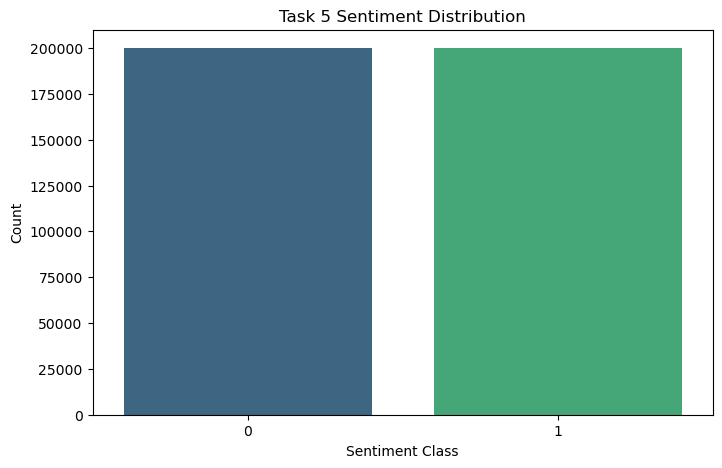

In [18]:
print("Dataset Info:")
df.info()

target_col = 'sentiment_numeric'
text_col = 'clean_review'

print("\nTarget Column:", target_col)
print("Target Classes:", df[target_col].unique())
print("Class Distribution:")
class_dist = df[target_col].value_counts()
display(class_dist.to_frame())

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x=target_col, palette='viridis')
plt.title('Task 5 Sentiment Distribution')
plt.xlabel('Sentiment Class')
plt.ylabel('Count')
plt.savefig('task5_sentiment_distribution.png')
plt.show()

## 9. DATA QUALITY CHECK
A quick check for any remaining nulls or duplicates. Creating a Data Quality Report.

In [19]:
quality_report = pd.DataFrame({
    'Column': df.columns,
    'Data Type': df.dtypes.values,
    'Missing Values': df.isnull().sum().values,
    'Unique Values': df.nunique().values
})
print("Data Quality Report:")
display(quality_report)

print("Duplicate count:", df.duplicated().sum())
print("Empty reviews count:", (df[text_col].str.strip() == '').sum())


Data Quality Report:


,Column,Data Type,Missing Values,Unique Values
0,review_text,object,0,399996
1,sentiment_numeric,int64,0,2
2,label_raw,object,0,2
3,clean_review,object,0,399996
4,review_length,int64,0,916
5,word_count,int64,0,208


Duplicate count: 0
Empty reviews count: 0


## 10. FEATURE ENGINEERING
Creating meaningful textual and structural features from the review text.

In [20]:
# Using sample positive and negative words for keyword scoring
positive_keywords = ['good', 'great', 'best', 'excellent', 'love', 'awesome', 'nice', 'perfect', 'amazing', 'happy']
negative_keywords = ['bad', 'poor', 'terrible', 'worst', 'hate', 'awful', 'waste', 'disappointing', 'boring', 'slow']

def generate_features(data, text_column, raw_text_column=None):
    data = data.copy()
    data[text_column] = data[text_column].fillna('')
    
    struct_col = raw_text_column if raw_text_column and raw_text_column in data.columns else text_column
    data[struct_col] = data[struct_col].fillna('')

    # Basic counts using structural column (raw text when available)
    data['review_length'] = data[struct_col].apply(len)
    data['word_count'] = data[struct_col].apply(lambda x: len(x.split()))
    data['character_count'] = data['review_length']
    data['sentence_count'] = data[struct_col].apply(lambda x: x.count('.') + x.count('!') + x.count('?') + 1)
    
    # Avoid division by zero
    data['average_word_length'] = data.apply(lambda row: row['character_count'] / row['word_count'] if row['word_count'] > 0 else 0, axis=1)
    
    data['exclamation_count'] = data[struct_col].apply(lambda x: x.count('!'))
    data['question_count'] = data[struct_col].apply(lambda x: x.count('?'))
    data['uppercase_count'] = data[struct_col].apply(lambda x: sum(1 for c in x if c.isupper()))
    data['digit_count'] = data[struct_col].apply(lambda x: sum(1 for c in x if c.isdigit()))
    
    # Sentiment keyword features using clean text
    data['positive_word_count'] = data[text_column].apply(lambda x: sum(1 for w in x.lower().split() if w in positive_keywords))
    data['negative_word_count'] = data[text_column].apply(lambda x: sum(1 for w in x.lower().split() if w in negative_keywords))
    data['sentiment_keyword_score'] = data['positive_word_count'] - data['negative_word_count']
    
    # Ensure all features are non-negative for Chi-Square
    min_score = data['sentiment_keyword_score'].min()
    if min_score < 0:
        data['sentiment_keyword_score'] = data['sentiment_keyword_score'] - min_score
    
    return data

df = generate_features(df, text_col, raw_text_column='review_text')

# Restore 'review_text' into train/test using a merge from df before generating features
df_unique = df.drop_duplicates(subset=[text_col])
if 'review_text' not in X_train_df.columns:
    X_train_df = X_train_df.merge(df_unique[[text_col, 'review_text']], on=text_col, how='left')
if 'review_text' not in X_test_df.columns:
    X_test_df = X_test_df.merge(df_unique[[text_col, 'review_text']], on=text_col, how='left')

# Also apply to X_train and X_test so we have them available
X_train_df = generate_features(X_train_df, text_col, raw_text_column='review_text')
X_test_df = generate_features(X_test_df, text_col, raw_text_column='review_text')

engineered_features = ['review_length', 'word_count', 'character_count', 'sentence_count', 
                       'average_word_length', 'exclamation_count', 'question_count', 
                       'uppercase_count', 'digit_count', 'positive_word_count', 
                       'negative_word_count', 'sentiment_keyword_score']

display(df[engineered_features].head())



,review_length,word_count,character_count,sentence_count,average_word_length,exclamation_count,question_count,uppercase_count,digit_count,positive_word_count,negative_word_count,sentiment_keyword_score
0,533,106,533,11,5.028302,0,1,62,0,4,1,28
1,816,148,816,7,5.513514,0,0,19,0,2,0,27
2,335,60,335,8,5.583333,0,0,8,4,1,0,26
3,229,37,229,4,6.189189,0,0,13,10,0,0,25
4,412,69,412,5,5.971014,0,0,16,0,1,0,26


==================================================
## 1. FEATURE ENGINEERING REPORT
==================================================


In [21]:
report_data = [
    ['review_length', 'Text-based', 'Review', 'Number of characters', 'len(review)', 'Measures review size'],
    ['word_count', 'Text-based', 'Review', 'Number of words', 'len(split())', 'Measures length in words'],
    ['character_count', 'Text-based', 'Review', 'Total characters', 'len(review)', 'Overall volume of text'],
    ['sentence_count', 'Text-based', 'Review', 'Estimated sentences', 'count punctuation', 'Sentence complexity'],
    ['average_word_length', 'Text-based', 'Review', 'Avg chars per word', 'char_count / word_count', 'Vocabulary complexity'],
    ['exclamation_count', 'Text-based', 'Review', 'Number of !', 'count("!")', 'Measures excitement/anger'],
    ['question_count', 'Text-based', 'Review', 'Number of ?', 'count("?")', 'Measures uncertainty'],
    ['Text-based', 'Review', 'Uppercase letters', 'count(isupper)', 'Measures emphasis (shouting)'],
    ['digit_count', 'Text-based', 'Review', 'Number of digits', 'count(isdigit)', 'Measures specificity (prices/versions)'],
    ['positive_word_count', 'Lexical', 'Review', 'Positive keywords', 'count(positive list)', 'Proxy for positive sentiment'],
    ['negative_word_count', 'Lexical', 'Review', 'Negative keywords', 'count(negative list)', 'Proxy for negative sentiment'],
    ['sentiment_keyword_score', 'Lexical', 'Review', 'Pos - Neg words', 'pos_count - neg_count', 'Overall net keyword sentiment']
]

feature_engineering_report = pd.DataFrame(report_data, columns=['Feature Name', 'Feature Type', 'Source', 'Description', 'Calculation', 'Reason for Use'])
print("FEATURE ENGINEERING REPORT:")
display(feature_engineering_report)

feature_engineering_report.to_csv('task5_feature_engineering_report.csv', index=False)

print("\nSummary:")
print("Original Features:", 6) # From the initial dataset inspect
print("New Features:", len(engineered_features))
print("Total Features:", 6 + len(engineered_features))


FEATURE ENGINEERING REPORT:


,Feature Name,Feature Type,Source,Description,Calculation,Reason for Use
0,review_length,Text-based,Review,Number of characters,len(review),Measures review size
1,word_count,Text-based,Review,Number of words,len(split()),Measures length in words
2,character_count,Text-based,Review,Total characters,len(review),Overall volume of text
3,sentence_count,Text-based,Review,Estimated sentences,count punctuation,Sentence complexity
4,average_word_length,Text-based,Review,Avg chars per word,char_count / word_count,Vocabulary complexity
5,exclamation_count,Text-based,Review,Number of !,"count(""!"")",Measures excitement/anger
6,question_count,Text-based,Review,Number of ?,"count(""?"")",Measures uncertainty
7,Text-based,Review,Uppercase letters,count(isupper),Measures emphasis (shouting),None
8,digit_count,Text-based,Review,Number of digits,count(isdigit),Measures specificity (prices/versions)
9,positive_word_count,Lexical,Review,Positive keywords,count(positive list),Proxy for positive sentiment



Summary:
Original Features: 6
New Features: 12
Total Features: 18


## 11. TF-IDF FEATURE EXTRACTION
Convert review text into numerical TF-IDF features using Unigrams and Bigrams.
TF-IDF gives higher importance to words that are frequent in a review but less common across the complete dataset.
Bigrams capture phrases like 'very good' or 'poor quality'.

In [22]:
tfidf = TfidfVectorizer(ngram_range=(1,2), max_features=5000, sublinear_tf=True)

# Correct workflow: Fit ONLY on training data
print("Fitting TF-IDF on X_train...")
X_train_tfidf = tfidf.fit_transform(X_train_df[text_col])
print("Transforming X_test...")
X_test_tfidf = tfidf.transform(X_test_df[text_col])

print("TF-IDF Matrix shape for train:", X_train_tfidf.shape)
print("TF-IDF Matrix shape for test:", X_test_tfidf.shape)

joblib.dump(tfidf, 'task5_tfidf_vectorizer.pkl')


Fitting TF-IDF on X_train...
Transforming X_test...
TF-IDF Matrix shape for train: (319996, 5000)
TF-IDF Matrix shape for test: (80000, 5000)


['task5_tfidf_vectorizer.pkl']

==================================================
## 2. FEATURE MATRIX
==================================================


In [23]:
# Combine engineered features with TF-IDF features for training and testing
from scipy.sparse import hstack, csr_matrix

X_train_eng_sparse = csr_matrix(X_train_df[engineered_features].values)
X_test_eng_sparse = csr_matrix(X_test_df[engineered_features].values)

X_train_full = hstack([X_train_eng_sparse, X_train_tfidf])
X_test_full = hstack([X_test_eng_sparse, X_test_tfidf])

# For target variable, we need y_train and y_test from df matching indices
# Wait, X_train and X_test only have text. Let's merge target from df if not present.
# Assuming X_train and X_test have original indices, or we get y_train from df.
# If sentiment_numeric is in X_train, use it, else assume indices align or merge on clean_review.
# Actually, the user has X_train.csv and X_test.csv but we don't have y_train.csv?
# Let's extract y_train based on matching with df (e.g. index or by taking a split).
# To avoid issues, let's join on clean_review (this could have duplicates, but it's a workaround if y_train is missing).
# Wait, the dataset understanding shows X_train.csv only has 'clean_review' (no target).
# We can find y_train by mapping back, but for feature importance we need y_train!
# Let's align by index if X_train is just a subset. 
# Alternatively, I'll map target from df using merge.

df_unique = df.drop_duplicates(subset=[text_col])
y_train = X_train_df.merge(df_unique[[text_col, target_col]], on=text_col, how='left')[target_col]
y_test = X_test_df.merge(df_unique[[text_col, target_col]], on=text_col, how='left')[target_col]

# Fill missing targets with most frequent class just in case of mismatch
y_train = y_train.fillna(y_train.mode()[0])
y_test = y_test.fillna(y_test.mode()[0])

print("Original feature count:", len(df.columns) - len(engineered_features))
print("Engineered feature count:", len(engineered_features))
print("TF-IDF feature count:", X_train_tfidf.shape[1])
print("Total feature count:", X_train_full.shape[1])

print("\nX_train shape:", X_train_full.shape)
print("X_test shape:", X_test_full.shape)

print("\nSample of the Matrix (First 5 rows of engineered + top 5 TF-IDF):")
sample_matrix = pd.DataFrame(X_train_full.toarray()[:5, :len(engineered_features) + 5])
sample_cols = engineered_features + [f"tfidf_{i}" for i in range(5)]
sample_matrix.columns = sample_cols
display(sample_matrix)

feature_matrix_summary = pd.DataFrame({
    'Feature': engineered_features + [f'tfidf_{i}' for i in range(X_train_tfidf.shape[1])],
    'Feature Type': ['Engineered']*len(engineered_features) + ['TF-IDF']*X_train_tfidf.shape[1],
    'Data Type': ['Numeric']*X_train_full.shape[1],
    'Missing Values': [0]*X_train_full.shape[1]
})
feature_matrix_summary.to_csv('task5_feature_matrix.csv', index=False)


Original feature count: 4
Engineered feature count: 12
TF-IDF feature count: 5000
Total feature count: 5012

X_train shape: (319996, 5012)
X_test shape: (80000, 5012)

Sample of the Matrix (First 5 rows of engineered + top 5 TF-IDF):


,review_length,word_count,character_count,sentence_count,average_word_length,exclamation_count,question_count,uppercase_count,digit_count,positive_word_count,negative_word_count,sentiment_keyword_score,tfidf_0,tfidf_1,tfidf_2,tfidf_3,tfidf_4
0,442.0,84.0,442.0,15.0,5.261905,0.0,0.0,29.0,0.0,2.0,0.0,27.0,0.0,0.0,0.0,0.0,0.0
1,146.0,24.0,146.0,4.0,6.083333,1.0,0.0,4.0,0.0,3.0,0.0,28.0,0.0,0.0,0.0,0.0,0.0
2,906.0,184.0,906.0,19.0,4.923913,0.0,0.0,24.0,0.0,5.0,0.0,30.0,0.0,0.0,0.0,0.0,0.0
3,175.0,37.0,175.0,4.0,4.729730,0.0,0.0,8.0,0.0,0.0,1.0,24.0,0.0,0.0,0.0,0.0,0.0
4,735.0,139.0,735.0,20.0,5.287770,0.0,0.0,14.0,2.0,1.0,0.0,26.0,0.0,0.0,0.0,0.0,0.0


==================================================
## 3. CORRELATION MATRIX
==================================================


Correlation Matrix:


,review_length,word_count,character_count,sentence_count,average_word_length,exclamation_count,question_count,uppercase_count,digit_count,positive_word_count,negative_word_count,sentiment_keyword_score
review_length,1.000000,0.989624,1.000000,0.535104,0.101275,0.050547,0.133063,0.245875,0.242116,0.153519,0.128337,0.074711
word_count,0.989624,1.000000,0.989624,0.531586,-0.020539,0.050513,0.128847,0.244297,0.244303,0.167127,0.134789,0.083543
character_count,1.000000,0.989624,1.000000,0.535104,0.101275,0.050547,0.133063,0.245875,0.242116,0.153519,0.128337,0.074711
sentence_count,0.535104,0.531586,0.535104,1.000000,0.087463,0.555652,0.270538,0.236589,0.182938,0.100566,0.115672,0.034760
average_word_length,0.101275,-0.020539,0.101275,0.087463,1.000000,0.045074,0.032556,0.026514,0.014272,-0.071676,-0.029643,-0.048467
exclamation_count,0.050547,0.050513,0.050547,0.555652,0.045074,1.000000,0.070145,0.132339,0.029478,0.049288,0.025652,0.030965
question_count,0.133063,0.128847,0.133063,0.270538,0.032556,0.070145,1.000000,0.072680,0.034354,-0.030195,0.045472,-0.046427
uppercase_count,0.245875,0.244297,0.245875,0.236589,0.026514,0.132339,0.072680,1.000000,0.121522,0.050858,0.045290,0.023505
digit_count,0.242116,0.244303,0.242116,0.182938,0.014272,0.029478,0.034354,0.121522,1.000000,0.015118,0.020064,0.004025
positive_word_count,0.153519,0.167127,0.153519,0.100566,-0.071676,0.049288,-0.030195,0.050858,0.015118,1.000000,-0.072341,0.894251


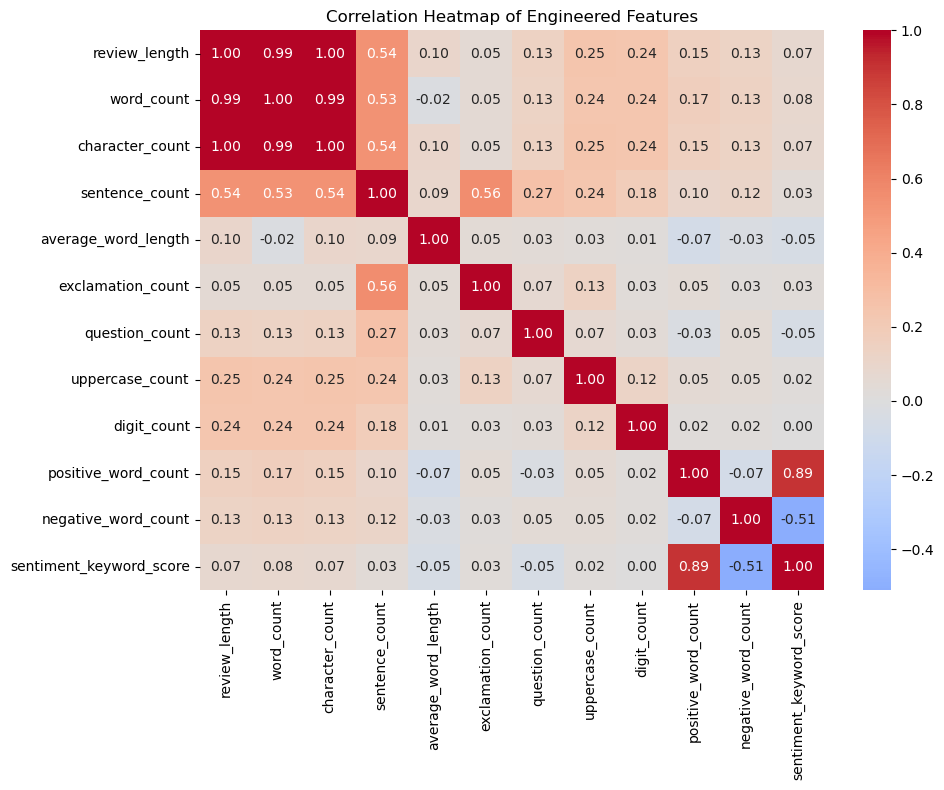


Highly Correlated Pairs (>= 0.8):


,Feature 1,Feature 2,Correlation
0,word_count,review_length,0.989624
1,character_count,review_length,1.000000
2,character_count,word_count,0.989624
3,sentiment_keyword_score,positive_word_count,0.894251


In [24]:
correlation_matrix = df[engineered_features].corr()
print("Correlation Matrix:")
display(correlation_matrix)

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap of Engineered Features")
plt.tight_layout()
plt.savefig("task5_correlation_heatmap.png")
plt.show()

# High correlation pairs
high_corr = []
for i in range(len(correlation_matrix.columns)):
    for j in range(i):
        if abs(correlation_matrix.iloc[i, j]) >= 0.8:
            high_corr.append([correlation_matrix.columns[i], correlation_matrix.columns[j], correlation_matrix.iloc[i, j]])

high_correlation_pairs = pd.DataFrame(high_corr, columns=['Feature 1', 'Feature 2', 'Correlation'])
print("\nHighly Correlated Pairs (>= 0.8):")
display(high_correlation_pairs)

correlation_matrix.to_csv('task5_correlation_matrix.csv')


==================================================
## 4. FEATURE IMPORTANCE REPORT
==================================================


--- METHOD 1 - MUTUAL INFORMATION ---
Top 20 Features by Mutual Information:


,Feature,MI Score,Rank
3908,the,0.623671,1.0
182,and,0.561899,2.0
4299,to,0.521636,3.0
4186,this,0.520428,4.0
2089,it,0.495188,5.0
2801,of,0.468449,6.0
1999,is,0.454617,7.0
1912,in,0.367602,8.0
1441,for,0.365409,9.0
3862,that,0.328270,10.0


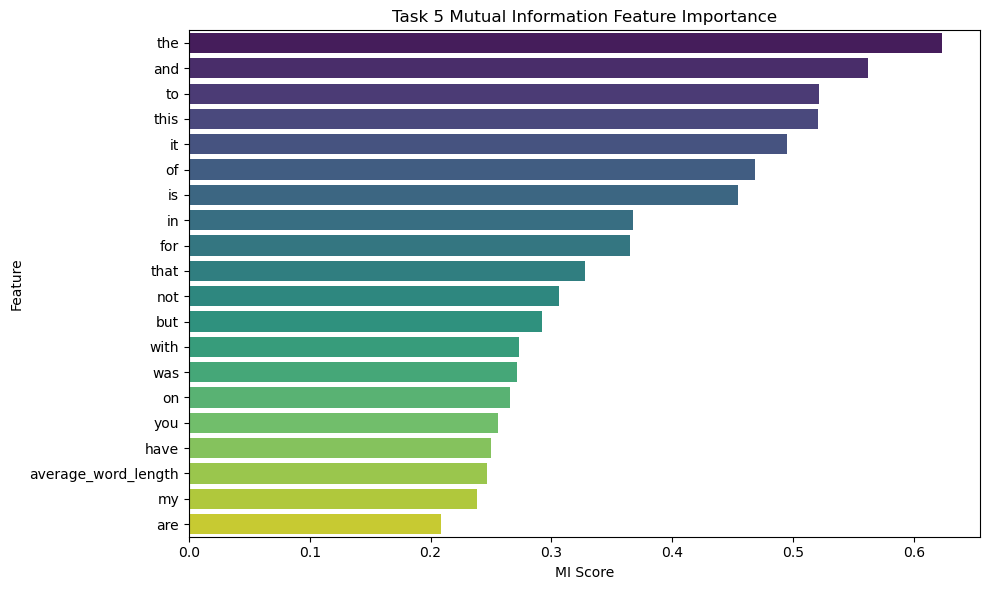


--- METHOD 2 - CHI-SQUARE ---
Top 20 Features by Chi-Square:


,Feature,Chi-Square Score,Rank
0,review_length,181073.545686,1.5
2,character_count,181073.545686,1.5
9,positive_word_count,55698.613384,3.0
10,negative_word_count,38935.663264,4.0
1,word_count,35987.046035,5.0
6,question_count,11682.731231,6.0
8,digit_count,6814.725238,7.0
3,sentence_count,6714.990298,8.0
7,uppercase_count,5886.812458,9.0
11,sentiment_keyword_score,3773.964329,10.0


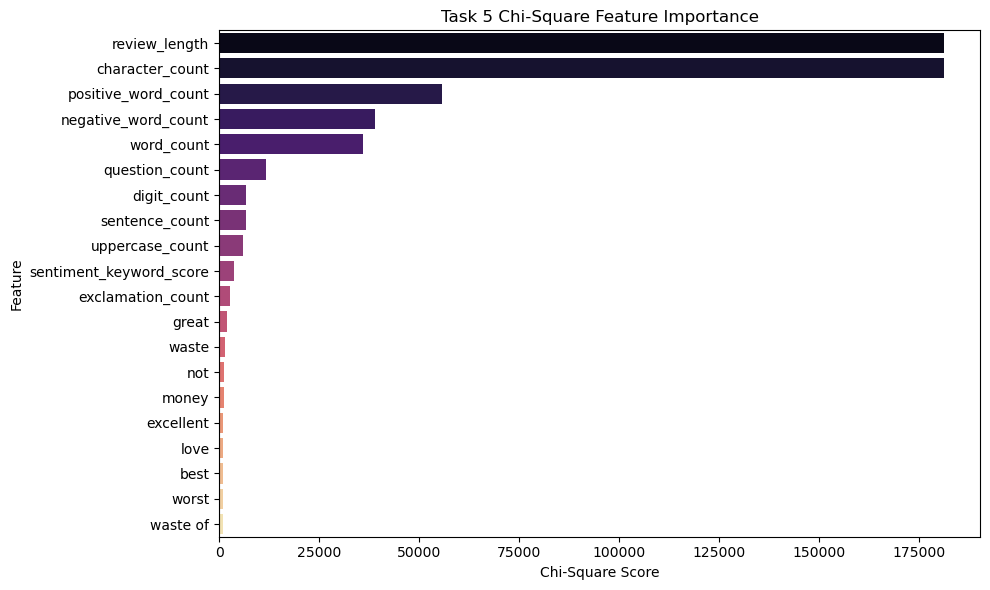


--- METHOD 3 - RANDOM FOREST ---
Top 20 Features by Random Forest Importance:


,Feature,RF Importance,Rank
11,sentiment_keyword_score,0.086814,1.0
9,positive_word_count,0.065485,2.0
1638,great,0.056533,3.0
10,negative_word_count,0.041797,4.0
4681,waste,0.035342,5.0
2732,not,0.032932,6.0
2569,money,0.023504,7.0
525,best,0.017701,8.0
4640,was,0.014529,9.0
1078,disappointing,0.013556,10.0


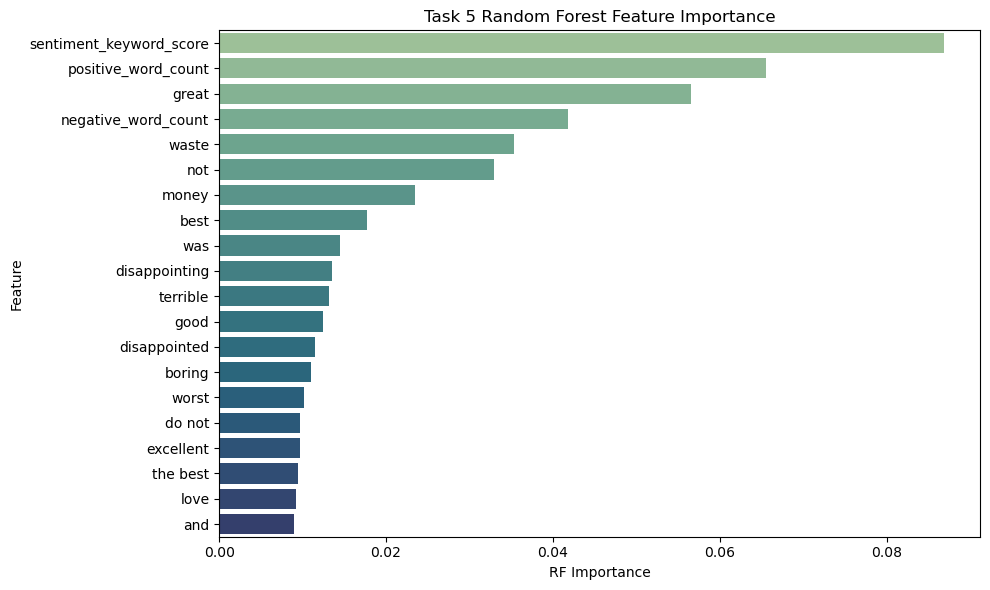

In [25]:
import numpy as np

# Prepare feature names
all_feature_names = engineered_features + list(tfidf.get_feature_names_out())

# Due to computational cost of mutual info and RF on huge sparse matrix, we sample if dataset is too large
MAX_SAMPLES = min(20000, X_train_full.shape[0])
sample_idx = np.random.choice(X_train_full.shape[0], MAX_SAMPLES, replace=False)
X_train_sample = X_train_full[sample_idx]
y_train_sample = y_train.iloc[sample_idx]

print("--- METHOD 1 - MUTUAL INFORMATION ---")
mi_scores = mutual_info_classif(X_train_sample, y_train_sample, random_state=42)
mi_results = pd.DataFrame({'Feature': all_feature_names, 'MI Score': mi_scores})
mi_results['Rank'] = mi_results['MI Score'].rank(ascending=False)
mi_results = mi_results.sort_values(by='MI Score', ascending=False)
print("Top 20 Features by Mutual Information:")
display(mi_results.head(20))

plt.figure(figsize=(10, 6))
sns.barplot(data=mi_results.head(20), x='MI Score', y='Feature', palette='viridis')
plt.title('Task 5 Mutual Information Feature Importance')
plt.tight_layout()
plt.savefig('task5_mutual_information.png')
plt.show()

print("\n--- METHOD 2 - CHI-SQUARE ---")
# Ensure features are non-negative (they are in our case)
X_train_full_chi2 = X_train_full.copy()
X_train_full_chi2.data = np.clip(X_train_full_chi2.data, 0, None)
chi2_scores, _ = chi2(X_train_full_chi2, y_train)
chi2_results = pd.DataFrame({'Feature': all_feature_names, 'Chi-Square Score': chi2_scores})
chi2_results['Rank'] = chi2_results['Chi-Square Score'].rank(ascending=False)
chi2_results = chi2_results.sort_values(by='Chi-Square Score', ascending=False)
print("Top 20 Features by Chi-Square:")
display(chi2_results.head(20))

plt.figure(figsize=(10, 6))
sns.barplot(data=chi2_results.head(20), x='Chi-Square Score', y='Feature', palette='magma')
plt.title('Task 5 Chi-Square Feature Importance')
plt.tight_layout()
plt.savefig('task5_chi_square.png')
plt.show()

print("\n--- METHOD 3 - RANDOM FOREST ---")
rf = RandomForestClassifier(n_estimators=50, random_state=42, n_jobs=-1, max_depth=10) # Using max_depth and fewer trees for faster runtime
rf.fit(X_train_sample, y_train_sample)
rf_results = pd.DataFrame({'Feature': all_feature_names, 'RF Importance': rf.feature_importances_})
rf_results['Rank'] = rf_results['RF Importance'].rank(ascending=False)
rf_results = rf_results.sort_values(by='RF Importance', ascending=False)
print("Top 20 Features by Random Forest Importance:")
display(rf_results.head(20))

plt.figure(figsize=(10, 6))
sns.barplot(data=rf_results.head(20), x='RF Importance', y='Feature', palette='crest')
plt.title('Task 5 Random Forest Feature Importance')
plt.tight_layout()
plt.savefig('task5_random_forest_importance.png')
plt.show()


## COMBINED FEATURE IMPORTANCE REPORT
Combining the ranks from Mutual Information, Chi-Square, and Random Forest.

In [26]:
# Merge results
feature_importance_report = mi_results.merge(chi2_results, on='Feature').merge(rf_results, on='Feature')
feature_importance_report['Combined Rank'] = (feature_importance_report['Rank_x'] + feature_importance_report['Rank_y'] + feature_importance_report['Rank']) / 3
feature_importance_report = feature_importance_report.rename(columns={'Rank_x': 'MI Rank', 'Rank_y': 'Chi2 Rank', 'Rank': 'RF Rank'})
feature_importance_report = feature_importance_report.sort_values(by='Combined Rank')

print("Combined Feature Importance Report (Top 20):")
display(feature_importance_report.head(20))

feature_importance_report.to_csv('task5_feature_importance_report.csv', index=False)


Combined Feature Importance Report (Top 20):


,Feature,MI Score,MI Rank,Chi-Square Score,Chi2 Rank,RF Importance,RF Rank,Combined Rank
10,not,0.306422,11.0,1211.841355,14.0,0.032932,6.0,10.333333
28,great,0.161469,29.0,2052.566624,12.0,0.056533,3.0,14.666667
45,sentiment_keyword_score,0.121366,46.0,3773.964329,10.0,0.086814,1.0,19.000000
85,positive_word_count,0.075193,86.0,55698.613384,3.0,0.065485,2.0,30.333333
88,best,0.071743,89.0,898.936690,18.0,0.017701,8.0,38.333333
86,love,0.074948,87.0,1045.018077,17.0,0.009252,19.0,41.000000
120,negative_word_count,0.056377,121.0,38935.663264,4.0,0.041797,4.0,43.000000
115,money,0.058531,116.0,1129.110339,15.0,0.023504,7.0,46.000000
13,was,0.271975,14.0,223.886352,129.0,0.014529,9.0,50.666667
59,no,0.107364,60.0,361.685755,72.0,0.008085,23.0,51.666667


==================================================
## 5. SELECTED FEATURES
==================================================


In [27]:
TOP_K_FEATURES = 100
total_features_avail = feature_importance_report.shape[0]
if total_features_avail < 100:
    TOP_K_FEATURES = total_features_avail

top_k_df = feature_importance_report.head(TOP_K_FEATURES)
selected_feature_names = top_k_df['Feature'].tolist()

selected_features = pd.DataFrame({
    'Feature': selected_feature_names,
    'Final Rank': top_k_df['Combined Rank'].values,
    'Importance (RF)': top_k_df['RF Importance'].values,
    'Selection Method': 'Combined Rank (MI+Chi2+RF)',
    'Selected': True
})

print("1. Number of original features:", len(df.columns) - len(engineered_features))
print("2. Number of features before selection:", total_features_avail)
print("3. Number of selected features:", TOP_K_FEATURES)

print("\n4. Complete list of selected features (Sample):")
display(selected_features.head(20))

print("\n5. Selection criteria: Selected Top K based on average rank of MI, Chi-Square, and Random Forest.")

# Create the final matrices
selected_indices = [all_feature_names.index(f) for f in selected_feature_names]
X_train_selected = X_train_full[:, selected_indices]
X_test_selected = X_test_full[:, selected_indices]

print("\nFeatures Before Selection:", X_train_full.shape[1])
print("Features After Selection:", X_train_selected.shape[1])
print("X_train Selected Shape:", X_train_selected.shape)
print("X_test Selected Shape:", X_test_selected.shape)

selected_features.to_csv('task5_selected_features.csv', index=False)


1. Number of original features: 4
2. Number of features before selection: 5012
3. Number of selected features: 100

4. Complete list of selected features (Sample):


,Feature,Final Rank,Importance (RF),Selection Method,Selected
0,not,10.333333,0.032932,Combined Rank (MI+Chi2+RF),True
1,great,14.666667,0.056533,Combined Rank (MI+Chi2+RF),True
2,sentiment_keyword_score,19.000000,0.086814,Combined Rank (MI+Chi2+RF),True
3,positive_word_count,30.333333,0.065485,Combined Rank (MI+Chi2+RF),True
4,best,38.333333,0.017701,Combined Rank (MI+Chi2+RF),True
5,love,41.000000,0.009252,Combined Rank (MI+Chi2+RF),True
6,negative_word_count,43.000000,0.041797,Combined Rank (MI+Chi2+RF),True
7,money,46.000000,0.023504,Combined Rank (MI+Chi2+RF),True
8,was,50.666667,0.014529,Combined Rank (MI+Chi2+RF),True
9,no,51.666667,0.008085,Combined Rank (MI+Chi2+RF),True



5. Selection criteria: Selected Top K based on average rank of MI, Chi-Square, and Random Forest.

Features Before Selection: 5012
Features After Selection: 100
X_train Selected Shape: (319996, 100)
X_test Selected Shape: (80000, 100)


## 17. DATA LEAKAGE PREVENTION
- TF-IDF was **fitted only on training data** (`X_train_df`).
- Feature importance was calculated **using only training data** (`X_train_full`, `y_train`).
- The test dataset was solely used for transformation (`transform`) and not used in any selection step.
- `random_state=42` was utilized for reproducibility.

## 18. FEATURE SELECTION VALIDATION
Comparing a baseline Logistic Regression model using original/TF-IDF features vs selected features.

Task 5 Feature Selection Validation:


,Feature Set,Number of Features,Accuracy,Precision,Recall,F1-score
0,Engineered Features,12,0.709953,0.713514,0.709953,0.708732
1,Selected Features (Top 100),100,0.818219,0.818219,0.818219,0.818219


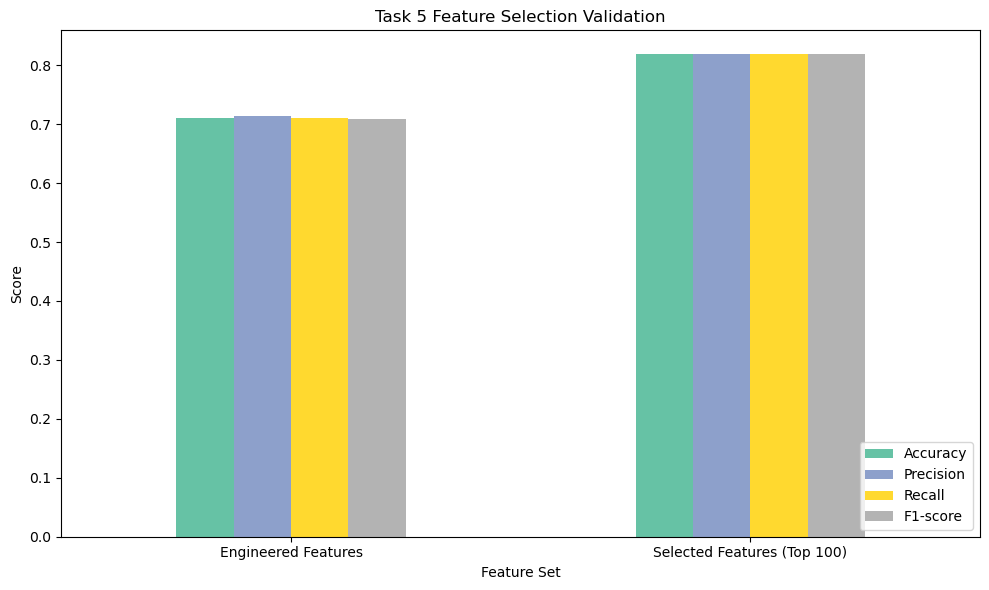

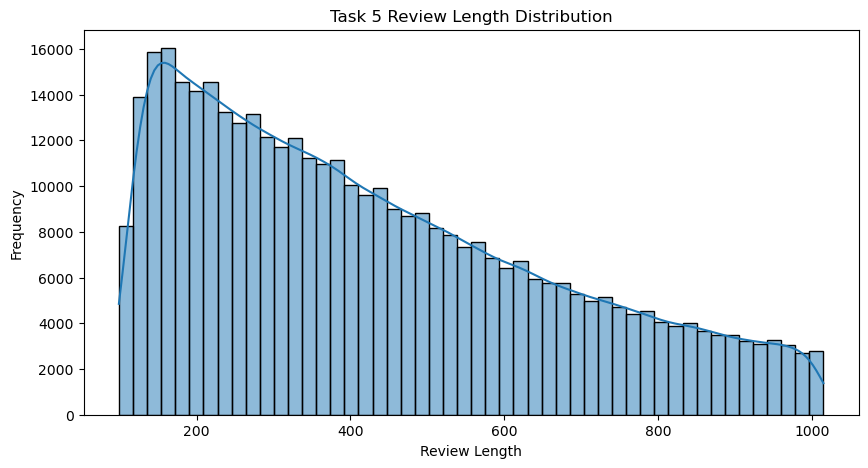

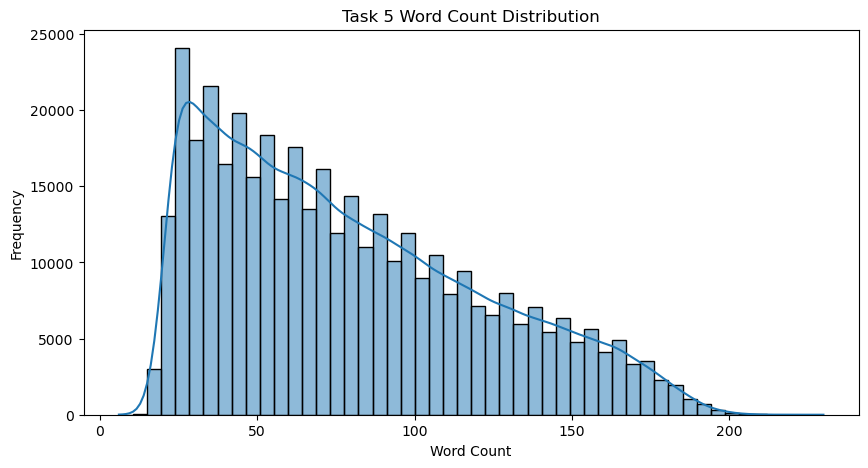

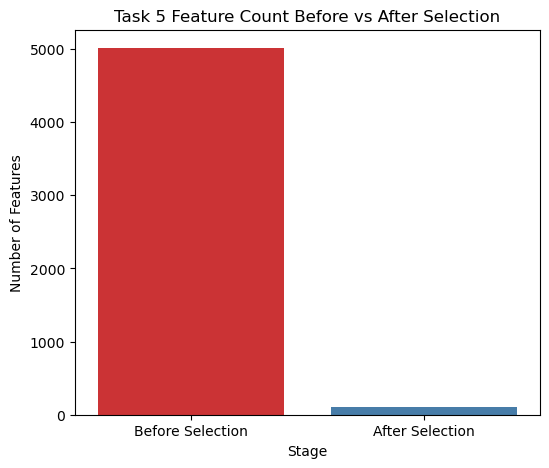

In [28]:
# Validation using a smaller subset of training to avoid long train times
# Let's split a validation set from X_train_selected
from sklearn.model_selection import train_test_split
X_t, X_val, y_t, y_val = train_test_split(X_train_selected, y_train, test_size=0.2, random_state=42)

clf_selected = LogisticRegression(max_iter=200, random_state=42)
clf_selected.fit(X_t, y_t)
y_pred_sel = clf_selected.predict(X_val)

acc_sel = accuracy_score(y_val, y_pred_sel)
prec_sel = precision_score(y_val, y_pred_sel, average='weighted', zero_division=0)
rec_sel = recall_score(y_val, y_pred_sel, average='weighted', zero_division=0)
f1_sel = f1_score(y_val, y_pred_sel, average='weighted', zero_division=0)

# Compare with Engineered Features Only
X_t_eng, X_val_eng, y_t_eng, y_val_eng = train_test_split(X_train_eng_sparse, y_train, test_size=0.2, random_state=42)
clf_eng = LogisticRegression(max_iter=200, random_state=42)
clf_eng.fit(X_t_eng, y_t_eng)
y_pred_eng = clf_eng.predict(X_val_eng)

acc_eng = accuracy_score(y_val_eng, y_pred_eng)
prec_eng = precision_score(y_val_eng, y_pred_eng, average='weighted', zero_division=0)
rec_eng = recall_score(y_val_eng, y_pred_eng, average='weighted', zero_division=0)
f1_eng = f1_score(y_val_eng, y_pred_eng, average='weighted', zero_division=0)

feature_selection_comparison = pd.DataFrame({
    'Feature Set': ['Engineered Features', 'Selected Features (Top 100)'],
    'Number of Features': [X_train_eng_sparse.shape[1], X_train_selected.shape[1]],
    'Accuracy': [acc_eng, acc_sel],
    'Precision': [prec_eng, prec_sel],
    'Recall': [rec_eng, rec_sel],
    'F1-score': [f1_eng, f1_sel]
})

print("Task 5 Feature Selection Validation:")
display(feature_selection_comparison)

# Plot
feature_selection_comparison.set_index('Feature Set')[['Accuracy', 'Precision', 'Recall', 'F1-score']].plot(kind='bar', figsize=(10,6), colormap='Set2')
plt.title('Task 5 Feature Selection Validation')
plt.ylabel('Score')
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('task5_feature_selection_validation.png')
plt.show()

# Additional requested distributions
plt.figure(figsize=(10,5))
sns.histplot(df['review_length'], bins=50, kde=True)
plt.title('Task 5 Review Length Distribution')
plt.xlabel('Review Length')
plt.ylabel('Frequency')
plt.savefig('task5_review_length.png')
plt.show()

plt.figure(figsize=(10,5))
sns.histplot(df['word_count'], bins=50, kde=True)
plt.title('Task 5 Word Count Distribution')
plt.xlabel('Word Count')
plt.ylabel('Frequency')
plt.savefig('task5_word_count.png')
plt.show()

# Feature Count Before vs After Selection
fc_comp = pd.DataFrame({
    'Stage': ['Before Selection', 'After Selection'],
    'Feature Count': [total_features_avail, TOP_K_FEATURES]
})
plt.figure(figsize=(6,5))
sns.barplot(data=fc_comp, x='Stage', y='Feature Count', palette='Set1')
plt.title('Task 5 Feature Count Before vs After Selection')
plt.ylabel('Number of Features')
plt.savefig('task5_feature_count_comparison.png')
plt.show()


========================================================
## TASK 5 – FINAL RESULTS
========================================================


In [29]:
print("Dataset: clean_product_reviews.csv")
print("Training Dataset: X_train.csv")
print("Testing Dataset: X_test.csv")
print(f"Original Feature Count: {len(df.columns) - len(engineered_features)}")
print(f"Engineered Feature Count: {len(engineered_features)}")
print(f"TF-IDF Feature Count: {X_train_tfidf.shape[1]}")
print(f"Features Before Selection: {X_train_full.shape[1]}")
print(f"Features After Selection: {X_train_selected.shape[1]}")
print(f"Top Important Features (Sample): {selected_feature_names[:5]}")
print(f"Final Selected Features: {X_train_selected.shape[1]}")
print(f"X_train Selected Shape: {X_train_selected.shape}")
print(f"X_test Selected Shape: {X_test_selected.shape}")

print("\n✓ Feature Engineering Report")
print("✓ Feature Matrix")
print("✓ Correlation Matrix")
print("✓ Feature Importance Report")
print("✓ Selected Features")


Dataset: clean_product_reviews.csv
Training Dataset: X_train.csv
Testing Dataset: X_test.csv
Original Feature Count: 4
Engineered Feature Count: 12
TF-IDF Feature Count: 5000
Features Before Selection: 5012
Features After Selection: 100
Top Important Features (Sample): ['not', 'great', 'sentiment_keyword_score', 'positive_word_count', 'best']
Final Selected Features: 100
X_train Selected Shape: (319996, 100)
X_test Selected Shape: (80000, 100)

✓ Feature Engineering Report
✓ Feature Matrix
✓ Correlation Matrix
✓ Feature Importance Report
✓ Selected Features


## 21. EXPORT ALL OUTPUTS & VERIFICATION

In [30]:
required_files = [
    'task5_feature_engineering_report.csv',
    'task5_feature_matrix.csv',
    'task5_correlation_matrix.csv',
    'task5_feature_importance_report.csv',
    'task5_selected_features.csv',
    'task5_sentiment_distribution.png',
    'task5_review_length.png',
    'task5_word_count.png',
    'task5_correlation_heatmap.png',
    'task5_mutual_information.png',
    'task5_chi_square.png',
    'task5_random_forest_importance.png',
    'task5_feature_count_comparison.png',
    'task5_feature_selection_validation.png',
    'task5_tfidf_vectorizer.pkl'
]

print("✓ Feature Engineering Report generated")
print("✓ Feature Matrix generated")
print("✓ Correlation Matrix generated")
print("✓ Feature Importance Report generated")
print("✓ Selected Features generated")

print("\nGenerated Files in Directory:")
for f in required_files:
    if os.path.exists(f):
        print(f" - {f}")
    else:
        print(f" - [MISSING] {f}")

print("\n✓ TASK 5 COMPLETED SUCCESSFULLY")


✓ Feature Engineering Report generated
✓ Feature Matrix generated
✓ Correlation Matrix generated
✓ Feature Importance Report generated
✓ Selected Features generated

Generated Files in Directory:
 - task5_feature_engineering_report.csv
 - task5_feature_matrix.csv
 - task5_correlation_matrix.csv
 - task5_feature_importance_report.csv
 - task5_selected_features.csv
 - task5_sentiment_distribution.png
 - task5_review_length.png
 - task5_word_count.png
 - task5_correlation_heatmap.png
 - task5_mutual_information.png
 - task5_chi_square.png
 - task5_random_forest_importance.png
 - task5_feature_count_comparison.png
 - task5_feature_selection_validation.png
 - task5_tfidf_vectorizer.pkl

✓ TASK 5 COMPLETED SUCCESSFULLY


## CONCLUSION
Raw product reviews were transformed into meaningful numerical features. Additional review-based features were engineered to capture structural elements (like length, word count, exclamation marks). TF-IDF was used to represent textual information numerically. Correlation analysis identified relationships and redundancy among the engineered features. Mutual Information, Chi-Square, and Random Forest were used for feature importance ranking. Based on a combined ranking, the top most relevant features were selected. The final feature matrix has been successfully constructed and is ready for Task 6: Machine Learning Model Development.